# Meshgrid test

Build, inspect, and test the existing **one-dimensional longitudinal grid**, before calculating RF fields or tracking electrons.

The five cavity positions and beam operating point follow the existing test notebook. Here the domain is set explicitly to \([-100, 2900]\) mm: it is a mesh-only example, not a field-map-derived domain.

Edit the input cell and **Run All**. The notebook does not load field maps, run MATLAB, or change solver files. The assertions test Python grid consistency; they are not yet a Python-MATLAB comparison.

The geometry plots are longitudinal cross-sections for orientation. There is no radial computational mesh, and the cavity markers do not represent cavity-wall shapes.

In [1]:
from pathlib import Path
from dataclasses import replace
import sys

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

current_directory = Path.cwd().resolve()
project_directory = next(
    path for path in (
        current_directory,
        current_directory / "pyKlyC",
        current_directory.parent,
    )
    if (path / "src" / "solver" / "grid.py").exists()
)
sys.path.insert(0, str(project_directory / "src"))

from constants import c, mu01
from model.beam import BeamParameters
from model.cavity import CavityParameters
from model.settings import NumericalSettings
from model.tube import TubeParameters
from solver.reference import ReferenceParameters
from solver.grid import GridParameters

np.set_printoptions(precision=6, linewidth=140)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


def show_table(rows):
    text = "| Variable | Value | Units | Meaning |\n"
    text += "|---|---|---|---|\n"
    for name, value, units, meaning in rows:
        if isinstance(value, np.ndarray):
            value = np.array2string(value, precision=5, max_line_width=1000)
        elif isinstance(value, (float, np.floating)):
            value = f"{value:.8g}"
        text += f"| `{name}` | {value} | {units} | {meaning} |\n"
    display(Markdown(text))

## 1. Editable inputs

All lengths below are in **mm**, frequencies in **GHz**, beam voltages in **kV**, and currents in **A**. Negative current represents electrons.

- `Nz` sets the requested spatial resolution per electronic wavelength.
- `Nt` sets the number of emission-phase samples per RF period. It does not set the spatial resolution.
- `rcv[0]` contains physical longitudinal positions; `rcv[1]` contains radius multipliers, so the physical tunnel radius is `rc * rcv[1]`.
- The other circuit and iteration parameters are supplied because the existing parameter classes require them. They do not trigger a circuit solution here.

In [2]:
# Beam and emission samples
Nbeam = 1
rm1 = 0.0
rm2 = 6.0
rc = 10.0
Nt = 128
t0 = 2.0 * np.pi * np.arange(Nt) / Nt
tn1 = t0.copy()
Y0 = np.arange(Nt)
Ut = np.full(Nt, 180.0)
Izt = np.full(Nt, -16.0)

# Cavity centers and RF parameters (no RF fields are calculated)
Nc = 5
f = 1.0
f0 = np.array([1.000, 1.006, 1.016, 1.030, 1.000])
zshift = np.array([0.0, 480.0, 1630.0, 2400.0, 2730.0])
type = np.array([0, 1, 1, 1, -1])
nh = np.ones(Nc, dtype=int)
Qext = np.array([334.0, 95000.0, 95000.0, 95000.0, 50.0])
Qin = np.array([16428.0, 19768.0, 19816.0, 16970.0, 14787.0])
Pin = np.array([60.0, 0.0, 0.0, 0.0, 0.0])
gaman = np.zeros(Nc, dtype=complex)
Lsb = np.pi * np.ones(Nc)
kai = np.zeros((Nc, Nc), dtype=complex)
cavityname = " ".join(f"guide_cavity_{k + 1}" for k in range(Nc))

# Explicit mesh-only domain and constant-radius tunnel
z0 = -100.0
L = 3000.0
rcv = np.array([
    [z0, z0 + L],
    [1.0, 1.0],
])

# Numerical parameters
Nz = 256
Ns = 8
factorregion = 10.0
Nlimit = 100
Ntimes = 10
Rlimit = 1.0e-4
iterfactor = 0.5

beam = BeamParameters(
    Nbeam=Nbeam, rm1=rm1, rm2=rm2, rc=rc,
    xb=0.0, yb=0.0, xd=0.0, yd=0.0,
    Nt=Nt, t0=t0, Ut=Ut, Izt=Izt, tn1=tn1, Y0=Y0,
)
cavities = CavityParameters(
    type=type, nh=nh, f0=f0, Qext=Qext, Qin=Qin,
    zshift=zshift, Pin=Pin, gaman=gaman, Lsb=Lsb,
    cavityname=cavityname, kai=kai,
)
tube = TubeParameters(z0=z0, L=L, rcv=rcv)
numerical = NumericalSettings(
    f=f, Nc=Nc, Ns=Ns, Nz=Nz, Nlimit=Nlimit,
    Ntimes=Ntimes, Rlimit=Rlimit, iterfactor=iterfactor,
    evolutionmethod=np.array([0.005, 2.0]),
    upstream_discard_distance_mm=0.0,
    efficiency_end_offset_mm=3.0 * rc,
)

reference = ReferenceParameters.calculate_reference_parameters(beam)
grid = GridParameters.calculate(
    numerical, cavities, tube, beam, reference, factorregion
)

## 2. Parameters and coordinate conversion

The electronic wavelength is the distance traveled at the reference speed \(v_0=s\,c\) in one RF period:

\[
\beta_e = \frac{\omega}{s\,c}\,10^{-3}\quad[\mathrm{mm}^{-1}],
\qquad
\lambda_e = \frac{2\pi}{\beta_e}\quad[\mathrm{mm}].
\]

The grid first requests \(\Delta z_i=\lambda_e/N_z\). It then fits an integer number of intervals into \(L\):

\[
N_{\mathrm{intervals}}=\left\lfloor\frac{L}{\lambda_e/N_z}\right\rfloor,
\qquad dz=\frac{L}{N_{\mathrm{intervals}}}.
\]

Consequently, `len(grid.z)` is **not** `Nz`, and the final spacing need not be exactly \(\lambda_e/N_z\).

\[
z=\beta_e\,z_i,\qquad dt=\beta_e\,dz.
\]

The code does not subtract `z0` when normalizing: if `z0 < 0`, the first normalized coordinate is negative too. `dt` is dimensionless, not seconds. Its physical time equivalent is `dt / w`, the time to travel one cell at \(v_0\).

In [3]:
lambdae = 2.0 * np.pi / grid.betae
dz_requested = lambdae / Nz

show_table([
    ("z0", z0, "mm", "Simulation entrance"),
    ("L", L, "mm", "Simulated length"),
    ("z0 + L", z0 + L, "mm", "Simulation exit"),
    ("Nz", Nz, "-", "Requested intervals per electronic wavelength"),
    ("len(grid.zi)", len(grid.zi), "-", "Actual number of longitudinal nodes"),
    ("len(grid.zi) - 1", len(grid.zi) - 1, "-", "Actual number of intervals"),
    ("lambdae", lambdae, "mm", "Reference electronic wavelength: 2*pi/betae"),
    ("lambdae / Nz", dz_requested, "mm", "Requested spacing before fitting L"),
    ("dz", grid.dz, "mm", "Final physical spacing"),
    ("zi", np.array([grid.zi[0], grid.zi[-1]]), "mm", "Physical coordinate endpoints"),
    ("z", np.array([grid.z[0], grid.z[-1]]), "-", "Normalized coordinate endpoints"),
    ("dt", grid.dt, "-", "Normalized spatial/time step: betae*dz"),
    ("dt / w", grid.dt / grid.w, "s", "Reference transit time across one cell"),
    ("f", f, "GHz", "Operating frequency"),
    ("w", grid.w, "rad/s", "Operating angular frequency"),
    ("betae", grid.betae, "1/mm", "Electronic propagation constant at f"),
    ("U0", reference.U0, "kV", "Reference beam voltage"),
    ("Iz0", reference.Iz0, "A", "Signed average beam current"),
    ("I0", reference.I0, "A", "Magnitude of average beam current"),
    ("s", reference.s, "-", "Reference speed divided by c"),
    ("s * c", reference.s * c, "m/s", "Reference beam speed"),
    ("gama", reference.gama, "-", "Reference Lorentz factor"),
    ("Nbeam", Nbeam, "-", "Number of identical beams"),
    ("rm1", rm1, "mm", "Inner beam radius; zero for a solid beam"),
    ("rm2", rm2, "mm", "Outer beam radius"),
    ("rc", rc, "mm", "Reference tunnel radius"),
    ("rcv[0]", rcv[0], "mm", "Tunnel-profile coordinate samples"),
    ("rcv[1]", rcv[1], "-", "Tunnel radius divided by rc at those samples"),
    ("rcvs", np.array([grid.rcvs.min(), grid.rcvs.max()]), "mm", "Min/max interpolated tunnel radius"),
    ("factorregion", factorregion, "-", "Space-charge source-window extent factor"),
    ("dN", grid.dN, "intervals", "floor(factorregion*rc/mu01/dz)"),
    ("Nesz.shape", grid.Nesz.shape, "-", "One [start, stop) source window per node"),
    ("Nt", Nt, "-", "Emission samples per RF period"),
    ("t0", np.array([t0[0], t0[-1]]), "rad", "Emission-phase endpoints; 2*pi is excluded"),
    ("2*pi/Nt", 2.0 * np.pi / Nt, "rad", "Emission-phase spacing, not dt"),
    ("tn1", np.array([tn1[0], tn1[-1]]), "rad", "Entrance phases; equal to t0 in this test"),
    ("Y0", f"0 ... {Y0[-1]}", "-", "Active particle indices, zero-based"),
    ("Ut", np.array([Ut.min(), Ut.max()]), "kV", "Min/max injected beam voltage"),
    ("Izt", np.array([Izt.min(), Izt.max()]), "A", "Min/max signed injected current"),
    ("Nc", Nc, "-", "Number of cavity markers"),
    ("Ns", Ns, "-", "Retained RF harmonics; does not set grid spacing"),
    ("Nlimit", Nlimit, "-", "Outer-iteration limit; unused in this test"),
    ("Ntimes", Ntimes, "-", "Trajectory-storage multiplier; unused here"),
    ("Rlimit", Rlimit, "-", "Convergence threshold; unused here"),
    ("iterfactor", iterfactor, "-", "Beam relaxation parameter; unused here"),
])

print("All per-cavity arrays are ordered by cavities.names:")
show_table([
    ("cavityname", cavities.names, "-", "Names, in cavity-column order"),
    ("type", type, "-", "0: input; 1: bunching; -1: output"),
    ("zshift", zshift, "mm", "Cavity-center positions"),
    ("nh", nh, "-", "Cavity harmonic numbers"),
    ("f0", f0, "GHz", "Resonant frequencies"),
    ("w0", grid.w0, "rad/s", "Resonant angular frequencies"),
    ("k0", grid.k0, "1/mm", "Vacuum wavenumbers at f0; distinct from betae"),
    ("Qext", Qext, "-", "External quality factors; unused here"),
    ("Qin", Qin, "-", "Intrinsic quality factors; unused here"),
    ("Pin", Pin, "W", "Incident powers; no circuit solve here"),
    ("gaman", gaman, "-", "Output reflection coefficients; unused here"),
    ("Lsb", Lsb, "rad", "Cavity-port electrical phase, not a grid spacing"),
    ("kai", "all zero", "-", "No inter-cavity coupling in this setup"),
])

| Variable | Value | Units | Meaning |
|---|---|---|---|
| `z0` | -100 | mm | Simulation entrance |
| `L` | 3000 | mm | Simulated length |
| `z0 + L` | 2900 | mm | Simulation exit |
| `Nz` | 256 | - | Requested intervals per electronic wavelength |
| `len(grid.zi)` | 3806 | - | Actual number of longitudinal nodes |
| `len(grid.zi) - 1` | 3805 | - | Actual number of intervals |
| `lambdae` | 201.80405 | mm | Reference electronic wavelength: 2*pi/betae |
| `lambdae / Nz` | 0.78829705 | mm | Requested spacing before fitting L |
| `dz` | 0.78843627 | mm | Final physical spacing |
| `zi` | [-100. 2900.] | mm | Physical coordinate endpoints |
| `z` | [-3.11351 90.29173] | - | Normalized coordinate endpoints |
| `dt` | 0.024548027 | - | Normalized spatial/time step: betae*dz |
| `dt / w` | 3.9069398e-12 | s | Reference transit time across one cell |
| `f` | 1 | GHz | Operating frequency |
| `w` | 6.2831853e+09 | rad/s | Operating angular frequency |
| `betae` | 0.031135081 | 1/mm | Electronic propagation constant at f |
| `U0` | 180 | kV | Reference beam voltage |
| `Iz0` | -16 | A | Signed average beam current |
| `I0` | 16 | A | Magnitude of average beam current |
| `s` | 0.67314584 | - | Reference speed divided by c |
| `s * c` | 2.0180405e+08 | m/s | Reference beam speed |
| `gama` | 1.3522472 | - | Reference Lorentz factor |
| `Nbeam` | 1 | - | Number of identical beams |
| `rm1` | 0 | mm | Inner beam radius; zero for a solid beam |
| `rm2` | 6 | mm | Outer beam radius |
| `rc` | 10 | mm | Reference tunnel radius |
| `rcv[0]` | [-100. 2900.] | mm | Tunnel-profile coordinate samples |
| `rcv[1]` | [1. 1.] | - | Tunnel radius divided by rc at those samples |
| `rcvs` | [10. 10.] | mm | Min/max interpolated tunnel radius |
| `factorregion` | 10 | - | Space-charge source-window extent factor |
| `dN` | 52 | intervals | floor(factorregion*rc/mu01/dz) |
| `Nesz.shape` | (3806, 2) | - | One [start, stop) source window per node |
| `Nt` | 128 | - | Emission samples per RF period |
| `t0` | [0.     6.2341] | rad | Emission-phase endpoints; 2*pi is excluded |
| `2*pi/Nt` | 0.049087385 | rad | Emission-phase spacing, not dt |
| `tn1` | [0.     6.2341] | rad | Entrance phases; equal to t0 in this test |
| `Y0` | 0 ... 127 | - | Active particle indices, zero-based |
| `Ut` | [180. 180.] | kV | Min/max injected beam voltage |
| `Izt` | [-16. -16.] | A | Min/max signed injected current |
| `Nc` | 5 | - | Number of cavity markers |
| `Ns` | 8 | - | Retained RF harmonics; does not set grid spacing |
| `Nlimit` | 100 | - | Outer-iteration limit; unused in this test |
| `Ntimes` | 10 | - | Trajectory-storage multiplier; unused here |
| `Rlimit` | 0.0001 | - | Convergence threshold; unused here |
| `iterfactor` | 0.5 | - | Beam relaxation parameter; unused here |


All per-cavity arrays are ordered by cavities.names:


| Variable | Value | Units | Meaning |
|---|---|---|---|
| `cavityname` | ('guide_cavity_1', 'guide_cavity_2', 'guide_cavity_3', 'guide_cavity_4', 'guide_cavity_5') | - | Names, in cavity-column order |
| `type` | [ 0  1  1  1 -1] | - | 0: input; 1: bunching; -1: output |
| `zshift` | [   0.  480. 1630. 2400. 2730.] | mm | Cavity-center positions |
| `nh` | [1 1 1 1 1] | - | Cavity harmonic numbers |
| `f0` | [1.    1.006 1.016 1.03  1.   ] | GHz | Resonant frequencies |
| `w0` | [6.28319e+09 6.32088e+09 6.38372e+09 6.47168e+09 6.28319e+09] | rad/s | Resonant angular frequencies |
| `k0` | [0.02096 0.02108 0.02129 0.02159 0.02096] | 1/mm | Vacuum wavenumbers at f0; distinct from betae |
| `Qext` | [3.34e+02 9.50e+04 9.50e+04 9.50e+04 5.00e+01] | - | External quality factors; unused here |
| `Qin` | [16428. 19768. 19816. 16970. 14787.] | - | Intrinsic quality factors; unused here |
| `Pin` | [60.  0.  0.  0.  0.] | W | Incident powers; no circuit solve here |
| `gaman` | [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j] | - | Output reflection coefficients; unused here |
| `Lsb` | [3.14159 3.14159 3.14159 3.14159 3.14159] | rad | Cavity-port electrical phase, not a grid spacing |
| `kai` | all zero | - | No inter-cavity coupling in this setup |


## 3. Longitudinal geometry and grid overview

The lower axis uses physical position `zi` in mm; the upper axis uses normalized position `z`. Cavity center lines are only location markers. The vertical coordinate is a signed transverse coordinate in a longitudinal cross-section, not a radial discretization.

For a hollow beam (`rm1 > 0`), the central region is left empty. The default solid beam has `rm1 = 0`.

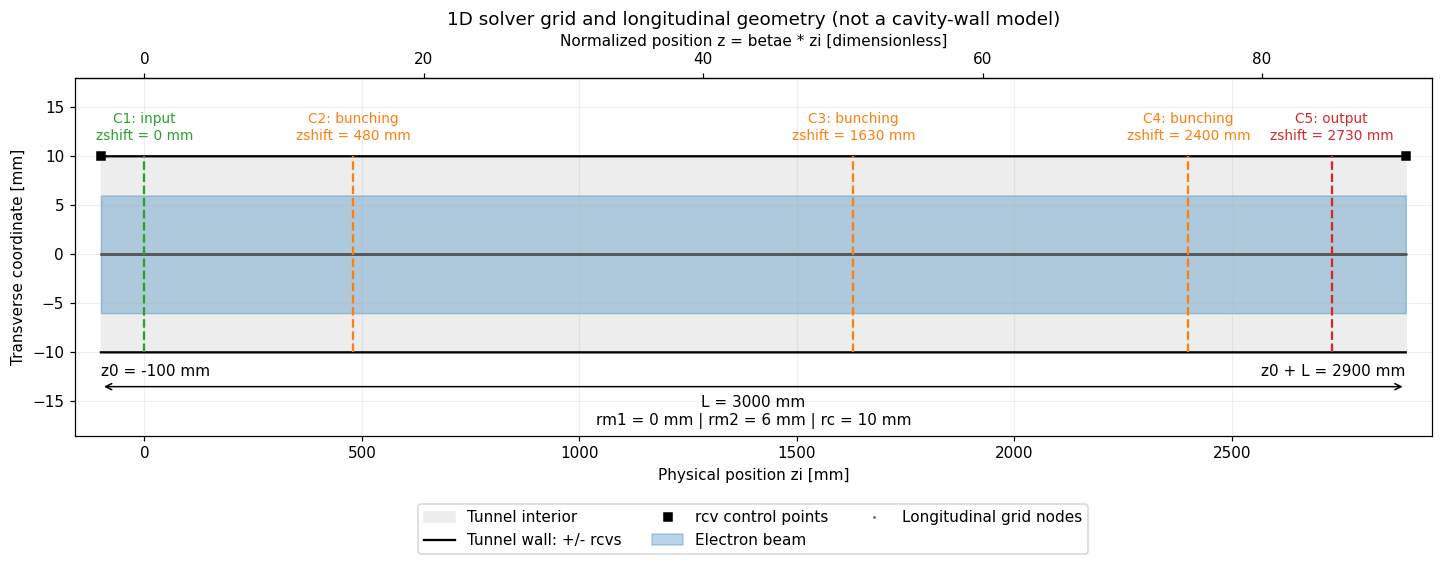

In [4]:
fig, ax = plt.subplots(figsize=(13, 5), layout="constrained")
radius = max(grid.rcvs.max(), rc)

ax.fill_between(grid.zi, -grid.rcvs, grid.rcvs, color="0.93", label="Tunnel interior")
ax.plot(grid.zi, grid.rcvs, color="black", label="Tunnel wall: +/- rcvs")
ax.plot(grid.zi, -grid.rcvs, color="black")
ax.plot(rcv[0], rc * rcv[1], "ks", markersize=5, label="rcv control points")

ax.fill_between(grid.zi, rm1, rm2, color="tab:blue", alpha=0.3, label="Electron beam")
ax.fill_between(grid.zi, -rm2, -rm1, color="tab:blue", alpha=0.3)
ax.plot(grid.zi, np.zeros_like(grid.zi), ".", color="0.35", markersize=1.5,
        label="Longitudinal grid nodes")

labels = {0: "input", 1: "bunching", -1: "output"}
colors = {0: "tab:green", 1: "tab:orange", -1: "tab:red"}
for k in range(Nc):
    ax.vlines(zshift[k], -radius, radius, color=colors[type[k]], linestyle="--")
    ax.text(zshift[k], 1.14 * radius,
            f"C{k + 1}: {labels[type[k]]}\nzshift = {zshift[k]:g} mm",
            ha="center", va="bottom", color=colors[type[k]], fontsize=9)

ax.annotate("", xy=(z0, -1.35 * radius), xytext=(z0 + L, -1.35 * radius),
            arrowprops={"arrowstyle": "<->", "color": "black"})
ax.text(z0 + L / 2, -1.43 * radius, f"L = {L:g} mm", ha="center", va="top")
ax.text(z0, -1.12 * radius, f"z0 = {z0:g} mm", ha="left", va="top")
ax.text(z0 + L, -1.12 * radius, f"z0 + L = {z0 + L:g} mm", ha="right", va="top")
ax.text(0.5, 0.03, f"rm1 = {rm1:g} mm | rm2 = {rm2:g} mm | rc = {rc:g} mm",
        transform=ax.transAxes, ha="center")

top = ax.secondary_xaxis(
    "top", functions=(lambda zi: grid.betae * zi, lambda z: z / grid.betae)
)
top.set_xlabel("Normalized position z = betae * zi [dimensionless]")
ax.set(xlim=(z0 - 0.02 * L, z0 + 1.02 * L), ylim=(-1.85 * radius, 1.8 * radius),
       xlabel="Physical position zi [mm]", ylabel="Transverse coordinate [mm]",
       title="1D solver grid and longitudinal geometry (not a cavity-wall model)")
ax.grid(alpha=0.2)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)
plt.show()

## 4. Zoom: nodes, indices, and physical/normalized spacing

`kz` is a zero-based Python grid index. A MATLAB index for the same node would be `kz + 1`.

The first panel displays individual nodes near the middle of the domain. The second checks the spacing over the entire domain. Tiny floating-point differences in `np.diff(zi)` are expected even for a uniform mesh.

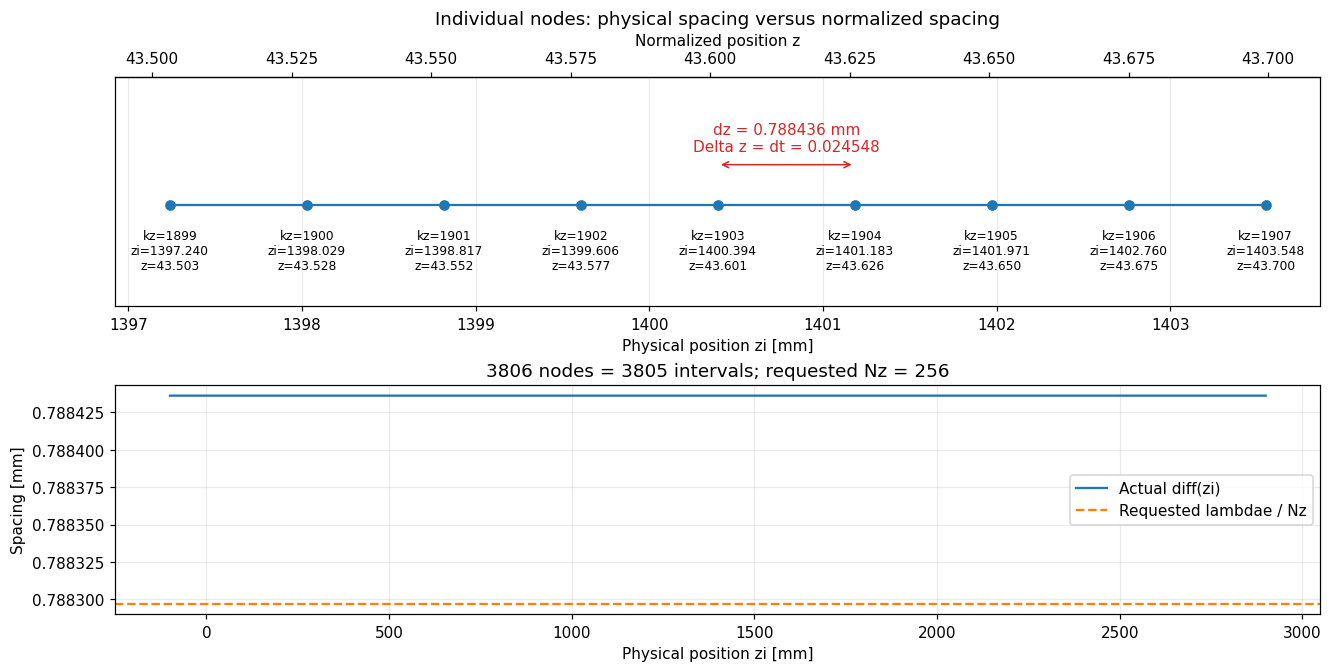

In [5]:
kz = len(grid.z) // 2
indices = np.arange(max(0, kz - 4), min(len(grid.z), kz + 5))
fig, axes = plt.subplots(2, 1, figsize=(12, 6), layout="constrained")

ax = axes[0]
ax.plot(grid.zi[indices], np.zeros(len(indices)), "o-", color="tab:blue")
for k in indices:
    ax.text(grid.zi[k], -0.18, f"kz={k}\nzi={grid.zi[k]:.3f}\nz={grid.z[k]:.3f}",
            ha="center", va="top", fontsize=8)
ax.annotate("", xy=(grid.zi[kz], 0.30), xytext=(grid.zi[kz + 1], 0.30),
            arrowprops={"arrowstyle": "<->", "color": "tab:red"})
ax.text((grid.zi[kz] + grid.zi[kz + 1]) / 2, 0.40,
        f"dz = {grid.dz:.6f} mm\nDelta z = dt = {grid.dt:.6f}",
        ha="center", color="tab:red")
top = ax.secondary_xaxis(
    "top", functions=(lambda zi: grid.betae * zi, lambda z: z / grid.betae)
)
top.set_xlabel("Normalized position z")
ax.set(ylim=(-0.75, 0.95), yticks=[], xlabel="Physical position zi [mm]",
       title="Individual nodes: physical spacing versus normalized spacing")
ax.grid(axis="x", alpha=0.25)

axes[1].plot(grid.zi[:-1], np.diff(grid.zi), label="Actual diff(zi)")
axes[1].axhline(dz_requested, color="tab:orange", linestyle="--",
                label="Requested lambdae / Nz")
axes[1].set(xlabel="Physical position zi [mm]", ylabel="Spacing [mm]",
            title=f"{len(grid.zi)} nodes = {len(grid.zi) - 1} intervals; requested Nz = {Nz}")
axes[1].ticklabel_format(axis="y", style="plain", useOffset=False)
axes[1].grid(alpha=0.25)
axes[1].legend()
plt.show()

## 5. Space-charge source windows: dN and Nesz

The grid stores the source indices that the global space-charge calculation will use:

\[
dN=\left\lfloor\frac{\mathrm{factorregion}\,r_c}{\mu_{01}\,dz}\right\rfloor.
\]

For a target node `kz`, `Nesz[kz] = [start, stop]` selects `grid.zi[start:stop]`: **start included, stop excluded**. Away from the boundaries this includes `2*dN + 1` points, including the target. At the entrance and exit, the window is clipped.

This only visualizes the in-domain source window. It does not calculate space charge or add the separate upstream prefill grid `zp`.

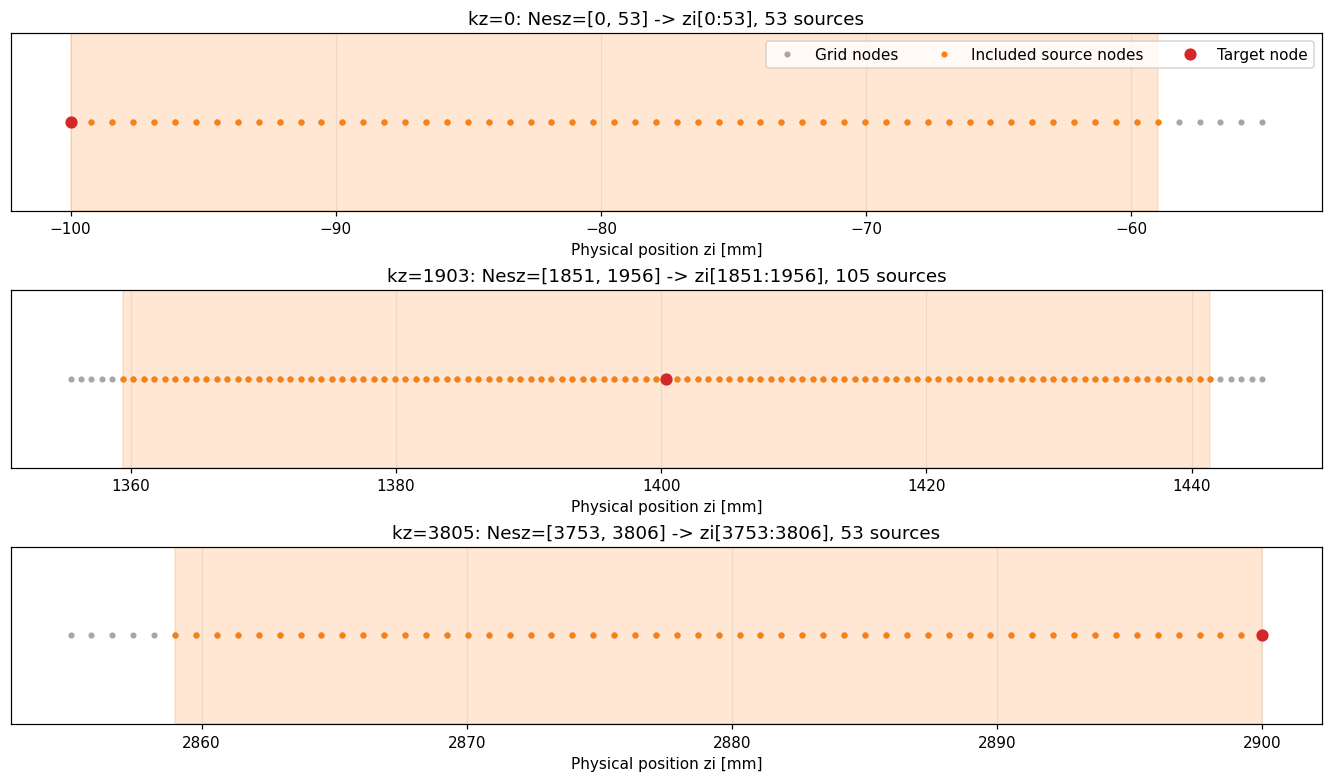

| Variable | Value | Units | Meaning |
|---|---|---|---|
| `Nesz[0]` | [0, 53) | indices | First zi=-100.0000 mm; last included zi=-59.0013 mm |
| `Nesz[1903]` | [1851, 1956) | indices | First zi=1359.3955 mm; last included zi=1441.3929 mm |
| `Nesz[3805]` | [3753, 3806) | indices | First zi=2859.0013 mm; last included zi=2900.0000 mm |


dN = 52; interior half-width = dN*dz = 40.998686 mm
Requested half-width = factorregion*rc/mu01 = 41.582981 mm


In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), layout="constrained")
window_rows = []

for ax, kz in zip(axes, [0, len(grid.z) // 2, len(grid.z) - 1]):
    start, stop = grid.Nesz[kz]
    view_start = max(0, start - 5)
    view_stop = min(len(grid.z), stop + 5)

    ax.plot(grid.zi[view_start:view_stop], np.zeros(view_stop - view_start),
            ".", color="0.65", label="Grid nodes")
    ax.axvspan(grid.zi[start], grid.zi[stop - 1], color="tab:orange", alpha=0.18)
    ax.plot(grid.zi[start:stop], np.zeros(stop - start), ".", color="tab:orange",
            label="Included source nodes")
    ax.plot(grid.zi[kz], 0, "o", color="tab:red", markersize=7, label="Target node")
    ax.set(ylim=(-0.5, 0.5), yticks=[], xlabel="Physical position zi [mm]",
           title=f"kz={kz}: Nesz=[{start}, {stop}] -> zi[{start}:{stop}], {stop - start} sources")
    ax.grid(axis="x", alpha=0.25)
    window_rows.append((
        f"Nesz[{kz}]", f"[{start}, {stop})", "indices",
        f"First zi={grid.zi[start]:.4f} mm; last included zi={grid.zi[stop - 1]:.4f} mm",
    ))

axes[0].legend(loc="upper right", ncol=3)
plt.show()
show_table(window_rows)
print(f"dN = {grid.dN}; interior half-width = dN*dz = {grid.dN * grid.dz:.6f} mm")
print(f"Requested half-width = factorregion*rc/mu01 = {factorregion * rc / mu01:.6f} mm")

## 6. Electron emission/entrance phases: separate from the spatial grid

\[
t_{0,j}=\frac{2\pi j}{N_t},\qquad j=0,\ldots,N_t-1.
\]

Here `tn1 = t0`: the two rows below coincide in phase but have different meanings. `t0` labels emission phases; `tn1` supplies entrance phases. Both are normalized times \(\omega t\), measured as phases in radians, not seconds. Future trajectory arrival phases will be stored separately in `Tnz`.

There is no sample at \(2\pi\): it would duplicate the start of the next RF period. The spacing \(2\pi/N_t\) is distinct from `grid.dt`, which comes from the spatial mesh.

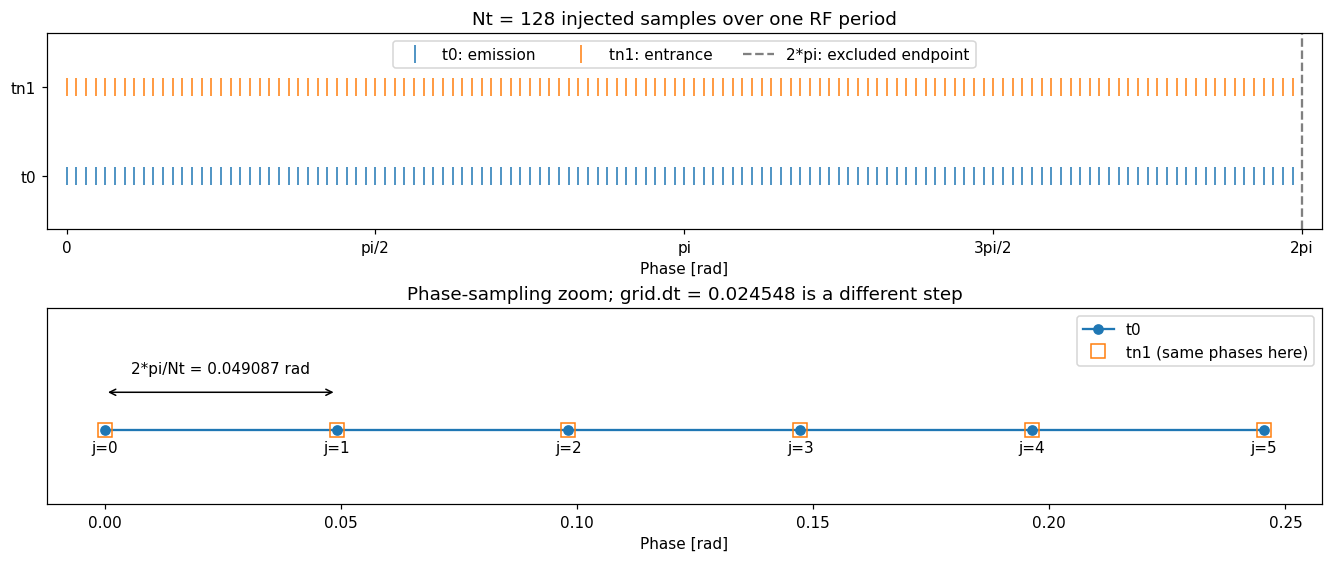

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), layout="constrained")
axes[0].plot(t0, np.zeros(Nt), "|", markersize=12, label="t0: emission")
axes[0].plot(tn1, np.ones(Nt), "|", markersize=12, label="tn1: entrance")
axes[0].axvline(2.0 * np.pi, color="0.5", linestyle="--", label="2*pi: excluded endpoint")
axes[0].set(xlim=(-0.1, 2.0 * np.pi + 0.1), ylim=(-0.6, 1.6),
            yticks=[0, 1], yticklabels=["t0", "tn1"], xlabel="Phase [rad]",
            title=f"Nt = {Nt} injected samples over one RF period")
axes[0].set_xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
                   ["0", "pi/2", "pi", "3pi/2", "2pi"])
axes[0].legend(loc="upper center", ncol=3)

indices = np.arange(min(6, Nt))
axes[1].plot(t0[indices], np.zeros(len(indices)), "o-", label="t0")
axes[1].plot(tn1[indices], np.zeros(len(indices)), "s", fillstyle="none",
             markersize=9, label="tn1 (same phases here)")
for j in indices:
    axes[1].text(t0[j], -0.12, f"j={j}", ha="center")
axes[1].annotate("", xy=(t0[0], 0.2), xytext=(t0[1], 0.2),
                 arrowprops={"arrowstyle": "<->"})
axes[1].text((t0[0] + t0[1]) / 2, 0.3, f"2*pi/Nt = {2*np.pi/Nt:.6f} rad", ha="center")
axes[1].set(ylim=(-0.4, 0.65), yticks=[], xlabel="Phase [rad]",
            title=f"Phase-sampling zoom; grid.dt = {grid.dt:.6f} is a different step")
axes[1].legend(loc="upper right")
plt.show()

## 7. Numerical tests of the baseline grid

These assertions check endpoints, interval count, uniformity, frequency conversions, radius interpolation, phase sampling, and all source-window bounds. They are **tests**, not additional validation code in the solver.

The input cell defines uniform `t0`, `tn1 = t0`, and a constant tunnel. The tests below describe those choices explicitly.

In [8]:
expected_intervals = int(np.floor(L / dz_requested))
assert len(grid.zi) == expected_intervals + 1
np.testing.assert_allclose(grid.zi[[0, -1]], [z0, z0 + L])
np.testing.assert_allclose(grid.dz, L / expected_intervals)
assert np.all(np.diff(grid.zi) > 0)
np.testing.assert_allclose(np.diff(grid.zi), grid.dz, rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(grid.z, grid.betae * grid.zi)
np.testing.assert_allclose(np.diff(grid.z), grid.dt, rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(grid.dt, grid.betae * grid.dz)
np.testing.assert_allclose(grid.dt / grid.w, grid.dz * 1e-3 / (reference.s * c))
np.testing.assert_allclose(grid.w, 2 * np.pi * f * 1e9)
np.testing.assert_allclose(grid.w0, 2 * np.pi * f0 * 1e9)
np.testing.assert_allclose(grid.k0, grid.w0 / c / 1e3)
np.testing.assert_allclose(grid.betae, grid.w / (reference.s * c) / 1e3)
assert grid.w0.shape == (Nc,)
assert grid.k0.shape == (Nc,)
assert grid.rcvs.shape == grid.zi.shape
np.testing.assert_allclose(grid.rcvs, rc)  # Constant-radius baseline
assert 0 <= rm1 < rm2 < grid.rcvs.min()
assert np.all((zshift >= z0) & (zshift <= z0 + L))

assert grid.dN == int(np.floor(factorregion * rc / mu01 / grid.dz))
assert grid.Nesz.shape == (len(grid.z), 2)
indices = np.arange(len(grid.z))
np.testing.assert_array_equal(grid.Nesz[:, 0], np.maximum(0, indices - grid.dN))
np.testing.assert_array_equal(grid.Nesz[:, 1], np.minimum(len(grid.z), indices + grid.dN + 1))
assert np.all(grid.Nesz[:, 0] <= indices)
assert np.all(grid.Nesz[:, 1] > indices)

np.testing.assert_array_equal(Y0, np.arange(Nt))
np.testing.assert_allclose(t0, 2 * np.pi * np.arange(Nt) / Nt)
np.testing.assert_allclose(tn1, t0)
np.testing.assert_allclose(np.diff(np.r_[t0, 2 * np.pi]), 2 * np.pi / Nt)
assert t0[-1] < 2 * np.pi

print("PASS: baseline grid, units, radii, indices, and phase sampling.")
print(f"Nodes: {len(grid.z)} | dz: {grid.dz:.9f} mm | dt: {grid.dt:.9f} | dN: {grid.dN}")

PASS: baseline grid, units, radii, indices, and phase sampling.
Nodes: 3806 | dz: 0.788436268 mm | dt: 0.024548027 | dN: 52


## 8. Controlled changes: which parameter changes what?

Each test below creates a separate object. The original `beam`, `tube`, `numerical`, and `grid` remain unchanged.

1. Double `Nz`: refine the spatial grid while keeping the physical endpoints.
2. Double `Nt`: refine emission-phase sampling without changing the grid for this same uniform beam.
3. Double `factorregion`: increase the source-window extent without changing grid coordinates.
4. Give `rcv` a varying radius: change `rcvs`, not the longitudinal coordinates. This test stays inside the supplied profile endpoints.

The integer rounding means doubling a requested resolution or window size does not necessarily double every resulting count exactly.

In [9]:
# 1. Finer longitudinal resolution
numerical_fine = replace(numerical, Nz=2 * Nz)
grid_fine = GridParameters.calculate(
    numerical_fine, cavities, tube, beam, reference, factorregion
)
assert len(grid_fine.z) > len(grid.z)
assert grid_fine.dz < grid.dz
np.testing.assert_allclose(grid_fine.zi[[0, -1]], grid.zi[[0, -1]])

# 2. More emission samples, same uniform beam operating point
Nt_fine = 2 * Nt
t0_fine = 2 * np.pi * np.arange(Nt_fine) / Nt_fine
beam_fine = replace(
    beam, Nt=Nt_fine, t0=t0_fine, tn1=t0_fine.copy(),
    Y0=np.arange(Nt_fine),
    Ut=np.full(Nt_fine, Ut[0]), Izt=np.full(Nt_fine, Izt[0]),
)
reference_fine = ReferenceParameters.calculate_reference_parameters(beam_fine)
grid_more_particles = GridParameters.calculate(
    numerical, cavities, tube, beam_fine, reference_fine, factorregion
)
np.testing.assert_allclose(grid_more_particles.zi, grid.zi)
np.testing.assert_allclose(grid_more_particles.z, grid.z)
np.testing.assert_allclose(np.diff(t0_fine), np.pi / Nt)
np.testing.assert_allclose(reference_fine.s, reference.s)

# 3. Wider source window
grid_wide = GridParameters.calculate(
    numerical, cavities, tube, beam, reference, 2 * factorregion
)
np.testing.assert_array_equal(grid_wide.zi, grid.zi)
assert grid_wide.dN > grid.dN
assert np.all(grid_wide.Nesz[:, 0] <= grid.Nesz[:, 0])
assert np.all(grid_wide.Nesz[:, 1] >= grid.Nesz[:, 1])

# 4. Varying tunnel radius, sampled on the same longitudinal grid
rcv_variable = np.array([
    [z0, z0 + 0.3 * L, z0 + 0.6 * L, z0 + L],
    [1.0, 1.0, 1.2, 1.0],
])
tube_variable = replace(tube, rcv=rcv_variable)
grid_variable = GridParameters.calculate(
    numerical, cavities, tube_variable, beam, reference, factorregion
)
np.testing.assert_array_equal(grid_variable.zi, grid.zi)
np.testing.assert_allclose(
    grid_variable.rcvs,
    np.interp(grid.zi, rcv_variable[0], rc * rcv_variable[1]),
)
# The existing dN formula uses the reference rc, not the varying rcvs.
np.testing.assert_array_equal(grid_variable.Nesz, grid.Nesz)

show_table([
    ("baseline", len(grid.z), "nodes", f"Nz={Nz}, Nt={Nt}, dz={grid.dz:.6f} mm, dN={grid.dN}"),
    ("2*Nz", len(grid_fine.z), "nodes", f"Finer spatial grid: dz={grid_fine.dz:.6f} mm"),
    ("2*Nt", beam_fine.Nt, "samples", "Twice as many phase samples; same grid"),
    ("2*factorregion", grid_wide.dN, "intervals", "Larger source-window half-width; same grid"),
    ("variable rcv", grid_variable.rcvs.max(), "mm", "Larger tunnel radius; same grid and Nesz"),
])
print("PASS: all four controlled-change tests.")

| Variable | Value | Units | Meaning |
|---|---|---|---|
| `baseline` | 3806 | nodes | Nz=256, Nt=128, dz=0.788436 mm, dN=52 |
| `2*Nz` | 7612 | nodes | Finer spatial grid: dz=0.394166 mm |
| `2*Nt` | 256 | samples | Twice as many phase samples; same grid |
| `2*factorregion` | 105 | intervals | Larger source-window half-width; same grid |
| `variable rcv` | 12 | mm | Larger tunnel radius; same grid and Nesz |


PASS: all four controlled-change tests.


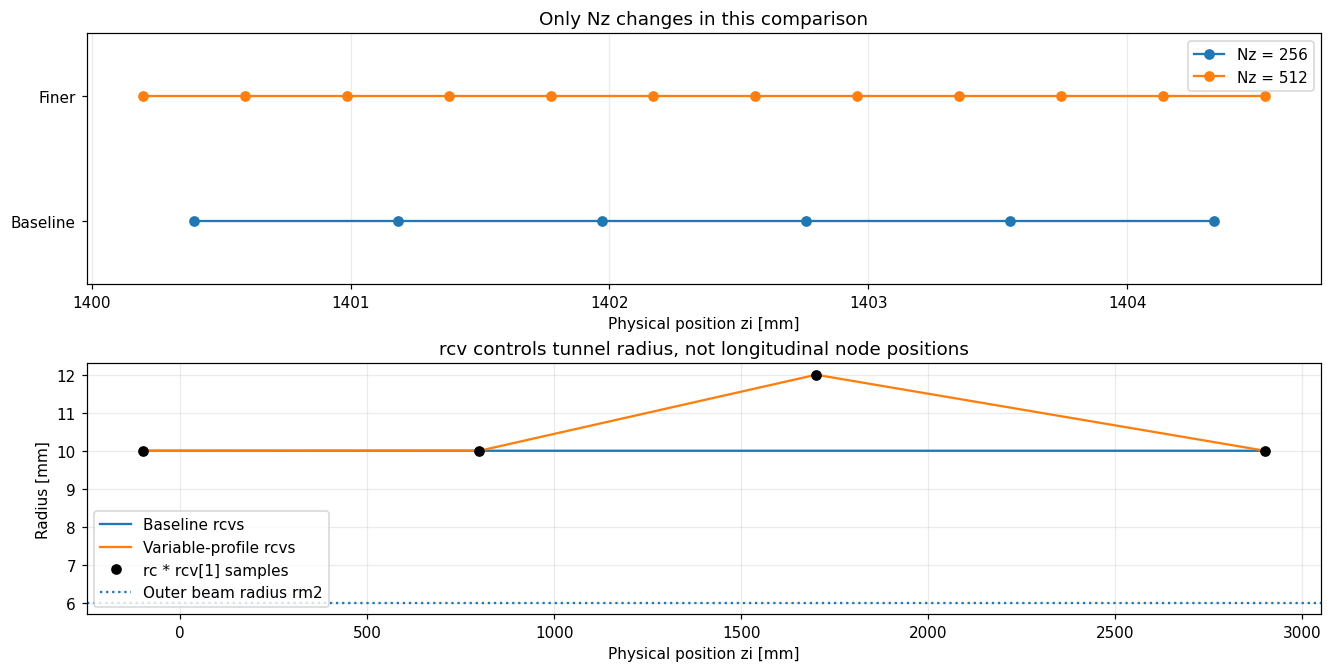

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), layout="constrained")

left = z0 + 0.5 * L
right = left + 6 * grid.dz
for mesh, y, label in [(grid, 0, f"Nz = {Nz}"), (grid_fine, 1, f"Nz = {2*Nz}")]:
    selected = (mesh.zi >= left) & (mesh.zi <= right)
    axes[0].plot(mesh.zi[selected], np.full(np.sum(selected), y), "o-", label=label)
axes[0].set(ylim=(-0.5, 1.5), yticks=[0, 1], yticklabels=["Baseline", "Finer"],
            xlabel="Physical position zi [mm]", title="Only Nz changes in this comparison")
axes[0].legend(loc="upper right")
axes[0].grid(axis="x", alpha=0.25)

axes[1].plot(grid.zi, grid.rcvs, label="Baseline rcvs")
axes[1].plot(grid_variable.zi, grid_variable.rcvs, label="Variable-profile rcvs")
axes[1].plot(rcv_variable[0], rc * rcv_variable[1], "ko", label="rc * rcv[1] samples")
axes[1].axhline(rm2, color="tab:blue", linestyle=":", label="Outer beam radius rm2")
axes[1].set(xlabel="Physical position zi [mm]", ylabel="Radius [mm]",
            title="rcv controls tunnel radius, not longitudinal node positions")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.show()

## What has been tested?

- Physical and normalized coordinates, final spacing, endpoint fitting, and array dimensions.
- Beam/tunnel geometry and cavity-center positions.
- Emission sampling versus longitudinal sampling.
- In-domain space-charge source windows and boundary clipping.
- The separate effects of `Nz`, `Nt`, `factorregion`, and `rcv`.

No RF cavity field, circuit solution, space-charge field, or particle trajectory has been calculated. Those are subsequent tests. A separate Python-MATLAB comparison is also still required.

To experiment, change `Nz`, `Nt`, `z0`, `L`, or `factorregion` in the input cell and rerun. Keep at least two phase samples and enough spatial nodes for the zooms. The constant-radius baseline assertion is intentionally specific to `rcv[1] = 1`; the variable-radius case is tested separately above.